---
title: ""
jupyter: cind860
execute:
  echo: false
bibliography: references.bib
csl: apa.csl
link-citations: true
format:
  pdf:
    documentclass: article
    pdf-engine: xelatex
    mainfont: "Times New Roman"
    fontsize: 12pt
    linestretch: 2
    geometry:
      - margin=1in
    fig-pos: "H"
    include-in-header:
      text: |
        \usepackage{setspace}
        \usepackage{indentfirst}
        \usepackage{float}
  html:
    title: "Sentiment Classification Interpretability on IMDb Movie Reviews Applying Shapley Additive Explanations (SHAP)"
    toc: true
    code-fold: true
    code-tools: true
    code-summary: "Show code"
    embed-resources: true
    execute:
      echo: true
---

```{=latex}
\begin{titlepage}
\begin{center}
\vspace*{2in}

{\large Sentiment Classification Interpretability on IMDb Movie Reviews\\
Applying Shapley Additive Explanations (SHAP)}

\vspace{1in}

Eileen Murphy \\
Student Number: 501113406

\vspace{1in}

Supervisor: Ashok Bhowmick, Ph.D

\vspace{1in}

Date of Submission: October 30, 2026

\end{center}
\end{titlepage}
```

```{=latex}
\begin{center}
\textbf{Abstract}
\end{center}
```

In this paper, we propose using the IMDb Movie Reviews dataset to conduct sentiment analysis and apply SHAP to understand the words or phrases that contribute to its score. Taking the sentiment analysis out of the "black box" to having transparent scores gives users the ability to validate and correct while improving the model over time. In this way, the model will become an asset rather than a potential unknown liability. The problem with artificial intelligence is not the effectiveness, but the trust of people using it. Models are not perfect and sometimes models will fail in just one reading, but that could be the only reading people see and dismiss the model entirely, as a result.

Using @krishnakumar2020towards as a theme, research on arrhythmias with different diagnosed classifications provides an insightful look on how different patterns in the range of their measurements can not only enhance their diagnosis but also make it transparent on which measurements were the most indicative of their condition. Another important aspect is the "bellwether" methodology to filter high quality instances to train the model to improve its performance scores.

## Proposed Approach

This research will train four classification models using Python SKLearn and/or KERAS:

1. Logistic Regression (TF-IDF)
2. Naive Bayes (TF-IDF)
3. Random Forest (TF-IDF)
4. LSTM (RNN) with Word Embeddings
5. DistilBERT Transformer (? Maybe)

SHAP values will be computed using Python SHAP packages on the models and compared to each other. Different plots will be generated to clarify how tokens affect the predictions.

"Bellwether" instances will be identified from partitioning the data (ie SHAP scores, movie genre, or other possibilities). Once the dataset is partitioned then we will run tests to see if a bellwether partition exists.  If there is a valid bellwether partition, then the model will be retrained on the bellwether subset. Finally, evaluation metrics will be calculated to assess model performance.

## Research Questions

RQ1: How do SHAP explanations differ across traditional ML, deep learning, and transformer models for sentiment classification?

RQ2: Does SHAP-based "bellwether" instance selection improve model performance? 

RQ3: Which sentiment-driving words are consensus across models, and which are model-specific?


## Introduction

The IMDB dataset has been used as a benchmark dataset for NLP sentiment analysis since 2011, and papers have been published by raising the accuracy of the previous study. As of this writing, it has reached 95-97% accuracy by 2019 [@ruder2019nlpprogress]. A link to the leaderboard of these scores and its respective authors' papers are a treasure trove of the historical evolving methods of achieving the highest accuracy as possible and the path getting us there.

Approaches used on NLP sentiment analysis used in studies reveal that attaining the highest accuracy is not linear and there are some tradeoffs between accuracy, robustness and computational cost. Testing and measuring the robustness of the model, in some cases tweaking the dataset to see how the model responds was not possible for "black box" models since their scoring was not transparent.  Meanwhile in 2017, a paper was published establishing a framework called SHAP(SHapley Additive exPlanations) [@lundberg2018shap]. By 2018, Python came out with the first version of the SHAP framework package. Being able to access the SHAP framework using Python made it possible for the higher performing "black box" models to be studied for their robustness in addition to their accuracy. Measuring robustness is not standardized, but using various techniques of comparison has shown that the new models are not just more accurate but more robust but only at the cost of increased computational processing. So now the challenge is finding the balance between accuracy, robustness, and computational processing. 


## Dataset

The IMDb Movies dataset will be used in this paper since it has been a reliable source for benchmarking for sentiment classification since 2011 and our results can be directly compared to other studies that still use it today. 

According to its documentation [@maas2011learning], the database contains 50K records split evenly between 25K for training and 25K for testing. 

Each record includes the raw text of the review, rating (1-10), sentiment (pos or neg). The sentiment is derived from the ratings. Ratings <= 4 are labeled negative, and ratings >= 7 are rated positive. There are no neutral ratings (5-6) included in the training or test datasets.

In the IMDB dataset there is another 50K records that include all the ratings (1-10). It does not include the derived sentiment from the ratings used in the labelled test and training sets. The purpose of including this dataset is for unsupervised learning. Although, we may use this dataset for our own purposes in this study. 

[IMDb Movies Database Source](https://ai.stanford.edu/~amaas/data/sentiment/) [@maas2011learning]


## Related Work

In the "Bellwethers: A Baseline Method For Transfer Learning" paper, published on January 2018 [@krishna2018bellwethersbaselinemethodtransfer] is a detailed and rigorous paper of establishing a bellwether subset of data and using transfer learning on the other partitioned subsets of data. This paper was written to solve the problem of software analytics prediction models coming to different conclusions as the number of projects increased. The author's study includes a rigorous identification of a bellwether subset, and making sure that the bellwether is tested periodically to make sure that it's still valid 

The author points out that finding a bellwether subset of data is more effective in a performance boost than by using more complex models on the whole dataset.

One  useful metric that can be used in this paper is the confusion square metric that calculates the result in a single value. The formula is as follows:

The paper defines G-Score as:

$$
G = \frac{2 \times P_d \times (1 - P_f)}{1 + P_d - P_f}
$$

Where:

- $P_d$ = Probability of Detection = $\dfrac{TP}{TP + FN}$ (Recall / True Positive Rate)
- $P_f$ = Probability of False Alarm = $\dfrac{FP}{FP + TN}$ (False Positive Rate) 
[@krishna2018bellwethersbaselinemethodtransfer]


"Explainable Sentiment Analysis: A Comparative Study of BERT, DistilBERT, and TF–IDF on the IMDB Dataset Using LIME and SHAP" [@khan2026explainable] compares traditional machine learning models and transformer based models using their accuracy scores. In addition, the models use LIME and SHAP model agnostic explanation frameworks to find token level importance, explainability, and robustness. 

To test robustness, it took out the top important tokens and noted the accuracy difference. Some models like SVM were dependent on some words for their accuracy scores while BERT maintained its accuracy even with 10% of the most important terms were dropped. The paper was concerned by not just performance scores but by whether the model was based on keyword tokens for their scores or if the model had a deeper understanding of the token taken in context. In its conclusion, DistilBERT model provided the best tradeoff between computation overhead, robustness, and accuracy scores.

A comparative study of using different machine learning and ensemble methods titled, "Binary Sentiment Classification on the IMDB Movie Review Dataset Using An Ensemble (Random Forest, Logistic Regression, and Xgboost) Approach." [@Dongre2025BinarySC] In this paper the authors compared using Logistic Regression, Random Forest, XGBoost, and Ensemble with detailed pre-processing and analysis for accuracy and F1 results and produced a confusion square for each test. The authors concluded that the Ensemble (Soft Voting) had the highest accuracy but only slightly above the Logistic Regression model, but was more stable.

The value of the "Advanced Sentiment Analysis of IMDB Movie Reviews Using NLP Preprocessing, TF-IDF and Classical Machine Learning Models" [@limbola2026advanced] is its detail on pre-processing and EDA analysis of the IMDB dataset and the description of the inner workings each machine model being examined. The authors compared Machine Learning models (Logistic Regression, SVM, Naive Bayes, Random Forest) with deep learning models (LSTM and BiLSTM). The test results showed that the Logistic Regression model is still a competitive model in its effectiveness, interpretation, and computational efficiency to be used as a baseline despite the advances in deep learning models.

"Sentiment Analysis on IMDB Reviews: A Comparative Study of Bag-of-Words, Deep Learning, and Transformer Models," [@shetty2026sentiment] is another comparison study but includes transformer architecture and compares Bag of Words (BOW), TF-IDF, and deep learning GloVe embeddings and pre-trained transformers. The conclusion was that the transformer model (Longformer) surpassed the other models (BERT and DistilBERT), and there is high potential to improve them.

## Methodology

```{mermaid}
%%| fig-width: 6.5
flowchart LR
    A["Feature Engineering<br/>TF-IDF, n-grams, embeddings"] --> B["Train 5 Classification Models"]

    B --> M1["Logistic Regression"]
    B --> M2["Naive Bayes"]
    B --> M3["Random Forest"]
    B --> M4["LSTM"]
    B --> M5["DistilBERT"]

    M1 --> S1["KernelSHAP"]
    M2 --> S1
    M3 --> S2["TreeSHAP"]
    M4 --> S3["GradientSHAP"]
    M5 --> S4["DeepSHAP"]

    S1 --> C["Compute SHAP Values"]
    S2 --> C
    S3 --> C
    S4 --> C

    C --> D["Identify 'Bellwether' Instances<br/>SHAP consistency metrics / partitions"]
    D --> E["Retrain Models on Bellwether Subset"]

    classDef feature fill:#cfe8ff,stroke:#1b6ec2,color:#000;
    classDef train fill:#d8f0d8,stroke:#2e7d32,color:#000;
    classDef explain fill:#fff3cd,stroke:#b08900,color:#000;
    classDef process fill:#f0e0ff,stroke:#7b2cbf,color:#000;

    class A feature;
    class B,M1,M2,M3,M4,M5 train;
    class S1,S2,S3,S4,C explain;
    class D,E process;
```


In [2]:
import time

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate


## Cleaned Data downloaded 25k training / 25k testing

In [3]:
import time

DATA_DIR = "data/IMDB Movies"

train = pd.read_csv(f"{DATA_DIR}/imdb_train.csv")
test = pd.read_csv(f"{DATA_DIR}/imdb_test.csv")

texts = train["text_clean"]
y = train["label"]  # numeric: 0 = neg, 1 = pos

print("train shape: ",train.shape, "test shape: ",test.shape)
train[["text_clean", "label", "rating"]].head()
# Reload fresh to be safe (train already in session, but let's confirm shape/columns)
print("Train columns: ",train.columns.tolist())

X_text = train["text_clean"]
y = train["label"]

train shape:  (25000, 4) test shape:  (25000, 4)
Train columns:  ['text_raw', 'text_clean', 'label', 'rating']


## Taking the 25k Training dataset and splitting it 80/20


In [4]:
#split train 80/20 using sklearn
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_text, y, test_size=0.2, stratify=y, random_state=42
)

print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("y_train:", y_train.shape, " y_test:", y_test.shape)
print("train class balance:\n", y_train.value_counts(normalize=True))
print("test class balance:\n", y_test.value_counts(normalize=True))

X_train: (20000,)  X_test: (5000,)
y_train: (20000,)  y_test: (5000,)
train class balance:
 label
1    0.5
0    0.5
Name: proportion, dtype: float64
test class balance:
 label
1    0.5
0    0.5
Name: proportion, dtype: float64


## Rating distribution

The distribution of the ratings is U shaped, while the sentiment (pos/neg) is evenly distributed


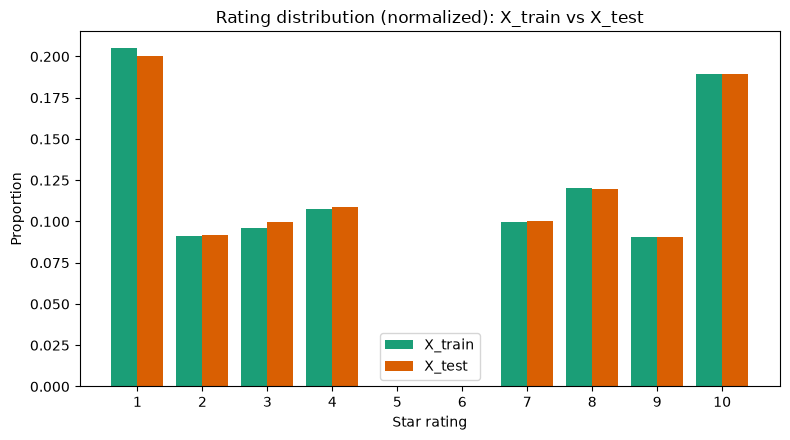

In [5]:
import numpy as np

ratings_train = train.loc[X_train.index, "rating"]
ratings_test = train.loc[X_test.index, "rating"]

bins = range(1, 12)
x = range(1, 11)
width = 0.4

train_counts, _ = np.histogram(ratings_train, bins=bins)
test_counts, _ = np.histogram(ratings_test, bins=bins)

train_prop = train_counts / train_counts.sum()
test_prop = test_counts / test_counts.sum()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar([i - width/2 for i in x], train_prop, width, label="X_train", color="#1b9e77")
ax.bar([i + width/2 for i in x], test_prop, width, label="X_test", color="#d95f02")

ax.set_xticks(x)
ax.set_xlabel("Star rating")
ax.set_ylabel("Proportion")
ax.set_title("Rating distribution (normalized): X_train vs X_test")
ax.legend()
fig.tight_layout()
plt.show()

The proportions line up closely across every rating value, confirming the stratified split preserved the original U-shaped rating distribution (ratings of 1 and 10 dominate, with no 5-6 ratings present).

## Review length distribution by label

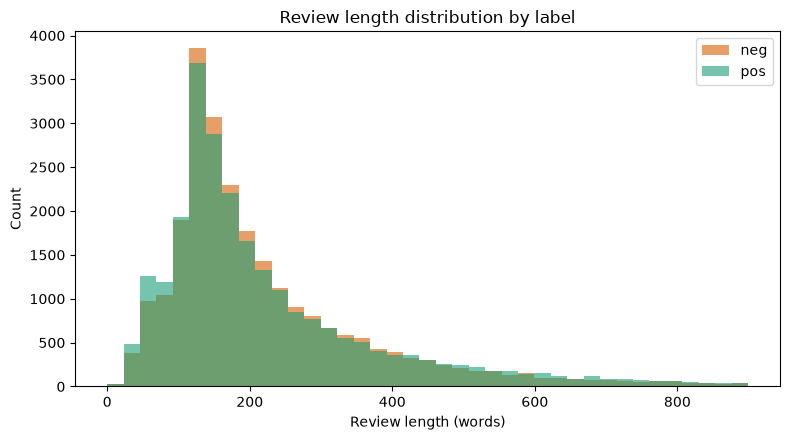

In [6]:
#| label: fig-wordcount-by-label-hist
combined = pd.concat([train, test], ignore_index=True)
combined["n_words"] = combined["text_clean"].str.split().str.len()

neg_len = combined.loc[combined["label"] == 0, "n_words"]
pos_len = combined.loc[combined["label"] == 1, "n_words"]

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(0, combined["n_words"].quantile(0.99), 40)
ax.hist(neg_len, bins=bins, alpha=0.6, label="neg", color="#d95f02")
ax.hist(pos_len, bins=bins, alpha=0.6, label="pos", color="#1b9e77")
ax.set_xlabel("Review length (words)")
ax.set_ylabel("Count")
ax.set_title("Review length distribution by label")
ax.legend()
fig.tight_layout()
plt.show()

The two distributions overlap almost completely and are both strongly right-skewed, confirming that review length does not meaningfully distinguish positive from negative reviews on average.

In [7]:
#| label: wordcount-by-label-stats
(
    combined
    .groupby("label")["n_words"]
    .agg(mean="mean", median="median", max="max", n="count")
    .reset_index()
)

,label,mean,median,max,n
0,0,227.87484,173.0,1509,25000
1,1,231.51840,171.0,2460,25000


## Review length distribution by split

In [8]:
#| label: wordcount-by-split-stats
combined2 = pd.concat(
    [train.assign(split="train"), test.assign(split="test")], ignore_index=True
)
combined2["n_words"] = combined2["text_clean"].str.split().str.len()

(
    combined2
    .groupby("split")["n_words"]
    .agg(mean="mean", median="median", max="max", n="count")
    .reset_index()
)

,split,mean,median,max,n
0,test,227.07664,171.0,2240,25000
1,train,232.31660,173.0,2460,25000


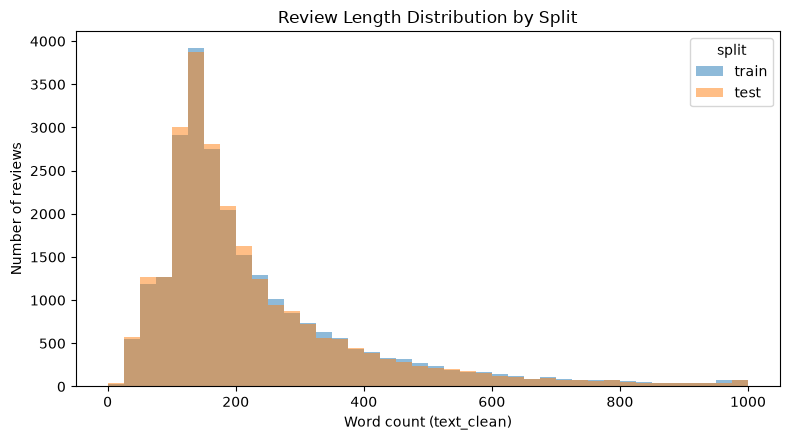

In [9]:
#| label: fig-wordcount-by-split-hist
train_len = combined2.loc[combined2["split"] == "train", "n_words"]
test_len = combined2.loc[combined2["split"] == "test", "n_words"]

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.arange(0, 1025, 25)
ax.hist(train_len[train_len <= 1000], bins=bins, alpha=0.5, label="train", color="#1f77b4")
ax.hist(test_len[test_len <= 1000], bins=bins, alpha=0.5, label="test", color="#ff7f0e")
ax.set_xlabel("Word count (text_clean)")
ax.set_ylabel("Number of reviews")
ax.set_title("Review Length Distribution by Split")
ax.legend(title="split")
fig.tight_layout()
plt.show()

Review length distributions are also very similar between the `train` and `test` splits, with closely matching means, medians, and overall shape. This indicates the train/test split does not introduce a length-based bias.

## Feature Extraction

### Unigrams using CountVectorizer

In [10]:
from sklearn.feature_extraction.text import CountVectorizer

import numpy as np

# Sample documents
reviews = X_train
    

# 1. UNIGRAM (single words)
unigram_vectorizer_counter = CountVectorizer(
    analyzer='word',
    ngram_range=(1, 1),  # Only unigrams
    lowercase=True,
    stop_words='english'
)


unigram_features_counter = unigram_vectorizer_counter.fit_transform(reviews)

#print("Unigram vocabulary:", unigram_vectorizer.get_feature_names_out())
print("Unigram counter matrix shape:", unigram_features_counter.shape)



print(f"Unigram features using counter")
n_rows, n_cols = unigram_features_counter.shape
uni = unigram_features_counter.nnz
density = uni / (n_rows * n_cols)
sparsity = 1 - density

print(f"Shape: {n_rows} x {n_cols}")
print(f"Non-zero entries: {uni:,}")
print(f"Density: {density:.6f} ({density*100:.4f}%)")
print(f"Sparsity: {sparsity:.6f} ({sparsity*100:.4f}%)")
print(f"Avg non-zero terms per document: {uni / n_rows:.1f}")

term_freq_counter = np.asarray(unigram_features_counter.sum(axis=0)).ravel()
vocab_counter = unigram_vectorizer_counter.get_feature_names_out()

top_terms = pd.DataFrame({"term": vocab_counter, "freq_count": term_freq_counter}).sort_values("freq_count", ascending=False).head(15).reset_index(drop=True)
print(top_terms)

Unigram counter matrix shape: (20000, 70538)
Unigram features using counter
Shape: 20000 x 70538
Non-zero entries: 1,787,417
Density: 0.001267 (0.1267%)
Sparsity: 0.998733 (99.8733%)
Avg non-zero terms per document: 89.4
      term  freq_count
0    movie       35227
1     film       31240
2     like       16396
3     just       14247
4     good       12167
5     time       10204
6    story        9507
7   really        9413
8      bad        7411
9   people        7373
10   great        7247
11    dont        6877
12  movies        6563
13     way        6462
14    make        6438


### Unigrams using TF-IDF

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer


# Sample documents
#reviews = X_train # already defined above
    

unigram_vectorizer_tfid = TfidfVectorizer(
    analyzer='word',
    ngram_range=(1, 1),
    lowercase=True,
    stop_words='english')

unigram_features_tfid = unigram_vectorizer_tfid.fit_transform(reviews)
#print("Unigram vocabulary:", unigram_vectorizer.get_feature_names_out())
print("Unigram tfid matrix shape:", unigram_features_tfid.shape)


print(f"Unigram features using Tfid")
n_rows, n_cols = unigram_features_tfid.shape
uni = unigram_features_tfid.nnz
density = uni / (n_rows * n_cols)
sparsity = 1 - density

print(f"Shape: {n_rows} x {n_cols}")
print(f"Non-zero entries: {uni:,}")
print(f"Density: {density:.6f} ({density*100:.4f}%)")
print(f"Sparsity: {sparsity:.6f} ({sparsity*100:.4f}%)")
print(f"Avg non-zero terms per document: {uni / n_rows:.1f}")

term_freq_tfid = np.asarray(unigram_features_tfid.sum(axis=0)).ravel()
vocab_tfid = unigram_vectorizer_tfid.get_feature_names_out()

top_terms_tfid = pd.DataFrame({"term": vocab_tfid, "freq_tfid": term_freq_tfid}).sort_values("freq_tfid", ascending=False).head(15).reset_index(drop=True)
print(top_terms_tfid)

Unigram tfid matrix shape: (20000, 70538)
Unigram features using Tfid
Shape: 20000 x 70538
Non-zero entries: 1,787,417
Density: 0.001267 (0.1267%)
Sparsity: 0.998733 (99.8733%)
Avg non-zero terms per document: 89.4
      term   freq_tfid
0    movie  961.947329
1     film  776.245237
2     like  452.172358
3     just  427.665118
4     good  406.913264
5   really  342.762510
6    story  336.876896
7     time  334.326304
8      bad  322.648217
9    great  295.571260
10  movies  288.114173
11    dont  281.385490
12  people  280.529406
13   watch  258.280574
14   think  250.224006


### BiGrams using TF-IDF

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer


# Sample documents
#reviews = X_train # already defined above
    

bigram_vectorizer_tfidf = TfidfVectorizer(
    analyzer='word',
    ngram_range=(2, 2),
    lowercase=True,
    stop_words='english',
    min_df=2, #check cross-validation consistency
    max_df=0.60) 

bigram_features_tfidf = bigram_vectorizer_tfidf.fit_transform(reviews)
#print("Unigram vocabulary:", unigram_vectorizer.get_feature_names_out())
print("BiGram tfid matrix shape:", bigram_features_tfidf.shape)


print(f"Ngrams features using Tfid")
n_rows, n_cols = bigram_features_tfidf.shape
bi = bigram_features_tfidf.nnz
density = bi / (n_rows * n_cols)
sparsity = 1 - density

print(f"Shape: {n_rows} x {n_cols}")
print(f"Non-zero entries: {bi:,}")
print(f"Density: {density:.6f} ({density*100:.4f}%)")
print(f"Sparsity: {sparsity:.6f} ({sparsity*100:.4f}%)")
print(f"Avg non-zero terms per document: {bi / n_rows:.1f}")

term_freq_tfidf_2 = np.asarray(bigram_features_tfidf.sum(axis=0)).ravel()
vocab_tfidf_2 = bigram_vectorizer_tfidf.get_feature_names_out()

top_terms_tfidf = pd.DataFrame({"term": vocab_tfidf_2, "freq_tfidf_2": term_freq_tfidf_2}).sort_values("freq_tfidf_2", ascending=False).head(15).reset_index(drop=True)
print(top_terms_tfidf)

BiGram tfid matrix shape: (20000, 206203)
Ngrams features using Tfid
Shape: 20000 x 206203
Non-zero entries: 905,929
Density: 0.000220 (0.0220%)
Sparsity: 0.999780 (99.9780%)
Avg non-zero terms per document: 45.3
               term  freq_tfidf_2
0          ive seen     89.966367
1   special effects     60.650624
2         dont know     60.403217
3        waste time     55.315566
4        low budget     50.360572
5          year old     49.580197
6        good movie     48.616912
7        looks like     47.971454
8       watch movie     46.294976
9        movie just     45.876615
10          im sure     42.891206
11         new york     41.855528
12       dont think     41.317676
13        years ago     39.575503
14           sci fi     38.893582


## Cross-Validation on X_train

Cross-validation is run on `X_train`/`y_train` only (not the full 25k or
`X_test`), so that `X_test` remains an untouched development hold-out and
`imdb_test.csv` remains available later as the final blind test set.
Settings (TF-IDF `max_features=10000`, `min_df=2`, `max_df=0.95`;
5-fold `StratifiedKFold`) match the project's existing baseline
(`scripts/cv_model_comparison.py`) for comparability.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

### Rating distribution across CV folds

`StratifiedKFold` stratifies on the binary `label`, not on `rating`
directly, so it's worth checking that each fold's validation split still
preserves a similar U-shaped rating distribution to the overall `X_train`
set.

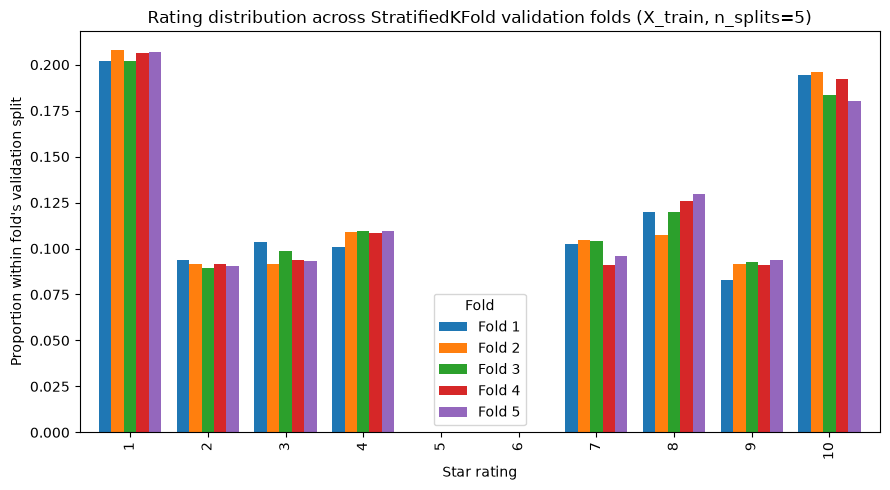

In [14]:
fold_rating_records = []

for fold_idx, (_, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
    val_ratings = train.loc[X_train.iloc[val_idx].index, "rating"]
    counts, _ = np.histogram(val_ratings, bins=range(1, 12))
    props = counts / counts.sum()
    for rating, prop in zip(range(1, 11), props):
        fold_rating_records.append(
            {"fold": f"Fold {fold_idx}", "rating": rating, "proportion": prop}
        )

fold_rating_df = pd.DataFrame(fold_rating_records)
fold_rating_pivot = fold_rating_df.pivot(index="rating", columns="fold", values="proportion")

fig, ax = plt.subplots(figsize=(9, 5))
fold_rating_pivot.plot(kind="bar", ax=ax, width=0.8)
ax.set_xlabel("Star rating")
ax.set_ylabel("Proportion within fold's validation split")
ax.set_title("Rating distribution across StratifiedKFold validation folds (X_train, n_splits=5)")
ax.legend(title="Fold")
fig.tight_layout()
plt.show()

## Initial Results

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
import time
import pandas as pd

scoring = {
    "accuracy": "accuracy",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Naive Bayes": MultinomialNB(),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=50,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=42),
}



# Define vectorizers
vectorizers = {
    "TF-IDF": TfidfVectorizer(max_features=10000, min_df=2, max_df=0.95),
    "CountVectorizer": CountVectorizer(max_features=10000, min_df=2, max_df=0.95),
    "bigram_vectorizer_tfidf": TfidfVectorizer(
        analyzer='word',
        ngram_range=(2, 2),
        lowercase=True,
        stop_words='english',
        min_df=2, #check cross-validation consistency
        max_df=0.95) 
}

cv_results = {}

# Loop through vectorizers and models
for vec_name, vectorizer in vectorizers.items():
    print(f"\n{'='*70}")
    print(f"VECTORIZER: {vec_name}")
    print(f"{'='*70}")
    
    for model_name, model in models.items():
        pipe = Pipeline([
            ("vectorizer", vectorizer),
            ("clf", model),
        ])
        
        t0 = time.time()
        results = cross_validate(
            pipe, X_train, y_train,
            cv=cv, scoring=scoring,
            return_train_score=True, n_jobs=-1,
        )
        elapsed = time.time() - t0
        
        # Store results with vectorizer info
        key = f"{vec_name} + {model_name}"
        cv_results[key] = results
        
        print(f"\n{model_name}  (elapsed {elapsed:.1f}s)")
        for metric in scoring:
            test_scores = results[f"test_{metric}"]
            train_scores = results[f"train_{metric}"]
            print(f"  {metric:10s} test: {test_scores.mean():.4f} (+/- {test_scores.std():.4f})   "
                  f"train: {train_scores.mean():.4f}")

# Save results to CSV
print("\n" + "="*70)
print("SAVING RESULTS...")
print("="*70)

results_summary = []
for key, results in cv_results.items():
    for metric in scoring:
        test_scores = results[f"test_{metric}"]
        train_scores = results[f"train_{metric}"]
        results_summary.append({
            'model': key,
            'metric': metric,
            'test_mean': test_scores.mean(),
            'test_std': test_scores.std(),
            'train_mean': train_scores.mean(),
        })

results_df = pd.DataFrame(results_summary)
results_df.to_csv("cv_results_comparison.csv", index=False)
print("✓ Results saved to: cv_results_comparison.csv")
print("\nResults Summary:")
print(results_df.pivot_table(index='model', columns='metric', values='test_mean'))


VECTORIZER: TF-IDF

Logistic Regression  (elapsed 50.2s)
  accuracy   test: 0.8859 (+/- 0.0026)   train: 0.9269
  f1         test: 0.8871 (+/- 0.0022)   train: 0.9274
  roc_auc    test: 0.9539 (+/- 0.0023)   train: 0.9791

Naive Bayes  (elapsed 40.0s)
  accuracy   test: 0.8562 (+/- 0.0048)   train: 0.8878
  f1         test: 0.8544 (+/- 0.0046)   train: 0.8864
  roc_auc    test: 0.9322 (+/- 0.0027)   train: 0.9565

Random Forest  (elapsed 130.7s)
  accuracy   test: 0.8411 (+/- 0.0043)   train: 0.9707
  f1         test: 0.8425 (+/- 0.0032)   train: 0.9710
  roc_auc    test: 0.9197 (+/- 0.0032)   train: 0.9964

VECTORIZER: CountVectorizer

Logistic Regression  (elapsed 44.8s)
  accuracy   test: 0.8679 (+/- 0.0044)   train: 0.9975
  f1         test: 0.8686 (+/- 0.0044)   train: 0.9975
  roc_auc    test: 0.9364 (+/- 0.0019)   train: 1.0000

Naive Bayes  (elapsed 44.1s)
  accuracy   test: 0.8395 (+/- 0.0056)   train: 0.8668
  f1         test: 0.8356 (+/- 0.0055)   train: 0.8635
  roc_auc   

In [20]:
# Create summary and find best model
summary = {}
for name in cv_results.keys():
    test_results = cv_results[name]
    summary[name] = {
        'accuracy': test_results['test_accuracy'].mean(),
        'accuracy_std': test_results['test_accuracy'].std(),
        'f1': test_results['test_f1'].mean(),
        'f1_std': test_results['test_f1'].std(),
    }

summary_df = pd.DataFrame(summary).T
print("\nCross-Validation Summary:")
print(summary_df.round(4))

# Choose best by F1 score
best_model_name = summary_df['accuracy'].idxmax()

# best_model_name is a combined "vectorizer + model" key (e.g. "TF-IDF + Logistic Regression"),
# since cv_results is now keyed that way by the single CV cell above.
best_vectorizer_name, best_model_label = best_model_name.split(" + ", 1)
best_vectorizer = vectorizers[best_vectorizer_name]
best_model = models[best_model_label]

print(f"\n{'='*50}")
print(f"Best Vectorizer + Model: {best_model_name}")
print(f"  Vectorizer: {best_vectorizer_name}")
print(f"  Model:      {best_model_label}")
print(f"CV Accuracy: {summary_df.loc[best_model_name, 'accuracy']:.4f} "
      f"(+/- {summary_df.loc[best_model_name, 'accuracy_std']:.4f})")
print(f"CV F1:       {summary_df.loc[best_model_name, 'f1']:.4f} "
      f"(+/- {summary_df.loc[best_model_name, 'f1_std']:.4f})")
print(f"{'='*50}")


Cross-Validation Summary:
                                               accuracy  accuracy_std      f1  \
TF-IDF + Logistic Regression                     0.8859        0.0026  0.8871   
TF-IDF + Naive Bayes                             0.8562        0.0048  0.8544   
TF-IDF + Random Forest                           0.8411        0.0043  0.8425   
CountVectorizer + Logistic Regression            0.8679        0.0044  0.8686   
CountVectorizer + Naive Bayes                    0.8395        0.0056  0.8356   
CountVectorizer + Random Forest                  0.8490        0.0039  0.8521   
bigram_vectorizer_tfidf + Logistic Regression    0.8427        0.0069  0.8475   
bigram_vectorizer_tfidf + Naive Bayes            0.8572        0.0067  0.8544   
bigram_vectorizer_tfidf + Random Forest          0.7631        0.0089  0.7884   

                                               f1_std  
TF-IDF + Logistic Regression                   0.0022  
TF-IDF + Naive Bayes                           0.0

In [21]:
#| label: tbl-cv-summary
cv_summary_table = (
    summary_df
    .reset_index(names="combo")
    .assign(
        vectorizer=lambda d: d["combo"].str.split(" + ", regex=False).str[0],
        model=lambda d: d["combo"].str.split(" + ", regex=False).str[1],
    )
    .loc[:, ["vectorizer", "model", "accuracy", "accuracy_std", "f1", "f1_std"]]
    .sort_values("accuracy", ascending=False)
    .round(4)
    .reset_index(drop=True)
)
cv_summary_table

,vectorizer,model,accuracy,accuracy_std,f1,f1_std
0,TF-IDF,Logistic Regression,0.8859,0.0026,0.8871,0.0022
1,CountVectorizer,Logistic Regression,0.8679,0.0044,0.8686,0.0044
2,bigram_vectorizer_tfidf,Naive Bayes,0.8572,0.0067,0.8544,0.0066
3,TF-IDF,Naive Bayes,0.8562,0.0048,0.8544,0.0046
4,CountVectorizer,Random Forest,0.8490,0.0039,0.8521,0.0029
5,bigram_vectorizer_tfidf,Logistic Regression,0.8427,0.0069,0.8475,0.0061
6,TF-IDF,Random Forest,0.8411,0.0043,0.8425,0.0032
7,CountVectorizer,Naive Bayes,0.8395,0.0056,0.8356,0.0055
8,bigram_vectorizer_tfidf,Random Forest,0.7631,0.0089,0.7884,0.0060


Table 1 (above) ranks all nine vectorizer/model combinations by cross-validated accuracy. TF-IDF + Logistic Regression achieved the highest cross-validated accuracy and F1 of all nine vectorizer/model combinations tested, consistent with the project's earlier baseline findings: Logistic Regression's linear decision boundary over sparse TF-IDF features suits this high-dimensional, near-linearly-separable bag-of-words text classification task well, while Naive Bayes' independence assumption and Random Forest's axis-aligned tree splits are comparatively less suited to sparse TF-IDF representations, and the bigram vectorizer under-performed unigram TF-IDF, likely due to increased feature sparsity without a compensating gain in discriminative signal.

The bigram TF-IDF vectorizer underperformed unigram TF-IDF for every model except Naive Bayes (0.857 vs. 0.856 accuracy, essentially unchanged), with the largest drops for Random Forest (0.763 vs. 0.841 accuracy, a 7.8-point loss) and Logistic Regression (0.843 vs. 0.886 accuracy, a 4.3-point loss), suggesting that bigrams' much sparser, higher-dimensional feature space dilutes the signal available per feature without a corresponding gain in discriminative information.

In [24]:
# Train best model on all training data
best_pipe = Pipeline([
    ("vectorizer", best_vectorizer),
    ("clf", best_model),
])


#print("X_train: ", X_train.shape, X_train.iloc[5])
#print("y_train: ", y_train.shape)
best_pipe.fit(X_train, y_train);  # trailing ';' suppresses the sklearn HTML-repr display output

In [25]:
# Step 5: Evaluate on test set
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

y_pred = best_pipe.predict(X_test)

print(f"\nFinal Test Set Evaluation:")
print(f"  Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"  F1:        {f1_score(y_test, y_pred):.4f}")
print(f"  Precision: {precision_score(y_test, y_pred):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred):.4f}")


Final Test Set Evaluation:
  Accuracy:  0.8762
  F1:        0.8774
  Precision: 0.8690
  Recall:    0.8860


Confusion matrix (rows = actual, cols = predicted):
                 Predicted neg   Predicted pos
  Actual neg              2166             334
  Actual pos               285            2215


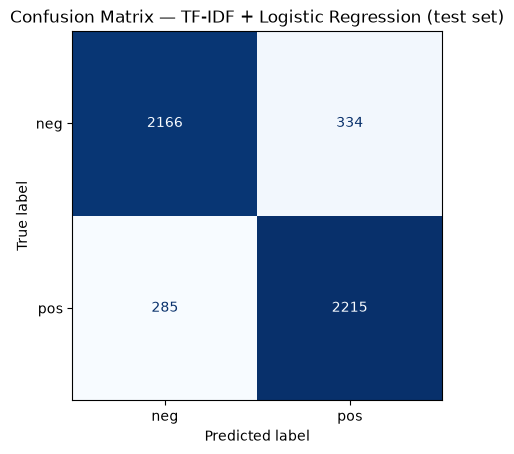

In [26]:
# Step 6: Confusion matrix for the final test-set predictions
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix (rows = actual, cols = predicted):")
print(f"                 Predicted neg   Predicted pos")
print(f"  Actual neg     {cm[0, 0]:>13}   {cm[0, 1]:>13}")
print(f"  Actual pos     {cm[1, 0]:>13}   {cm[1, 1]:>13}")

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["neg", "pos"]
)
disp.plot(cmap="Blues", colorbar=False)
plt.title(f"Confusion Matrix — {best_model_name} (test set)")
plt.show()

## SHAP Explanations (KernelSHAP) for the Best Model

With `best_pipe` identified above (TF-IDF + Logistic Regression), we compute
SHAP (SHapley Additive exPlanations) values using `shap.KernelExplainer`, a
model-agnostic explainer that treats the pipeline as a black box via its
`predict_proba` method.

KernelSHAP's runtime scales with both the number of background samples and
the number of instances explained, so two steps keep it tractable on a
10,000-feature TF-IDF representation:

1. **Background summarization**: rather than using the full 20,000-row
   `X_train` as the background distribution (which made `shap.kmeans` alone
   take ~14 minutes), we first randomly sample 300 training rows and then
   summarize those into 50 k-means cluster centers. This cuts background
   preparation to a few seconds with no meaningful loss in explanation
   quality.
2. **Explained sample size**: KernelSHAP is run on the first 50 reviews of
   `X_test` (with `nsamples=200` coalition samples per instance), which
   takes roughly a minute — enough to see clear, interpretable patterns
   without the cost of explaining the full test set.

SHAP values are cached to disk (one `.npz` file per model under
`shap_cache/`) after the first computation. The cache key encodes the
model name, explained sample size, and `nsamples`, so later sections (or
re-renders) that need these same SHAP values can load them in under a
second instead of re-running the KernelSHAP computation — and the cache
is automatically invalidated (recomputed) if any of those settings change.

In [27]:
#| label: shap-cache-helper
import os
import shap

def compute_or_load_shap(
    name, pipe, X_train, X_test,
    method="kernel", n_explain=50, nsamples=200, cache_dir="shap_cache",
):
    """Compute (or load cached) SHAP values for a fitted pipeline.

    `method="kernel"` uses model-agnostic KernelSHAP (appropriate for
    Logistic Regression and Naive Bayes, per the project's methodology
    diagram). `method="tree"` uses the exact, much faster TreeSHAP
    (appropriate for tree ensembles like Random Forest), computed with
    `feature_perturbation="interventional"` against the same background
    sample used for KernelSHAP, so values stay on a comparable probability
    scale and reference distribution across models.

    Caches to `shap_cache/shap_values_<slug>_<method>.npz`, keyed on model
    name, method, n_explain, and nsamples (for "kernel") so stale caches
    (including ones from a previously-used method) are auto-invalidated.
    """
    vectorizer = pipe.named_steps["vectorizer"]
    model = pipe.named_steps["clf"]
    feature_names = vectorizer.get_feature_names_out()

    slug = name.lower().replace(" ", "_").replace("+", "").replace("__", "_")
    cache_path = os.path.join(cache_dir, f"shap_values_{slug}_{method}shap.npz")
    cache_key = f"{name}|method={method}|n_explain={n_explain}|nsamples={nsamples}"

    X_explain_text = X_test.iloc[:n_explain]
    X_explain_vec = vectorizer.transform(X_explain_text).toarray()

    if os.path.exists(cache_path):
        cached = np.load(cache_path, allow_pickle=True)
        if str(cached["cache_key"]) == cache_key:
            print(f"[{name}] Loaded cached {method.upper()}SHAP values from {cache_path}.")
            return {
                "shap_values_pos": cached["shap_values_pos"],
                "feature_names": cached["feature_names"],
                "X_explain_vec": X_explain_vec,
                "X_explain_text": X_explain_text,
            }

    # Shared background: sample 300 training rows, then summarize to 50 k-means centers
    rng = np.random.RandomState(42)
    X_train_vec_sample = vectorizer.transform(
        X_train.iloc[rng.choice(len(X_train), size=300, replace=False)]
    ).toarray()
    background = shap.kmeans(X_train_vec_sample, 50)

    if method == "tree":
        explainer = shap.TreeExplainer(
            model, data=background.data,
            feature_perturbation="interventional", model_output="probability",
        )
        shap_values = explainer.shap_values(X_explain_vec)
    else:
        explainer = shap.KernelExplainer(model.predict_proba, background)
        shap_values = explainer.shap_values(X_explain_vec, nsamples=nsamples, silent=True)

    # SHAP values for the "pos" class (index 1)
    shap_values_pos = shap_values[:, :, 1] if np.ndim(shap_values) == 3 else shap_values[1]

    os.makedirs(cache_dir, exist_ok=True)
    np.savez_compressed(
        cache_path,
        shap_values_pos=shap_values_pos,
        feature_names=feature_names,
        cache_key=cache_key,
    )
    print(f"[{name}] Computed {method.upper()}SHAP values and cached them to {cache_path}.")

    return {
        "shap_values_pos": shap_values_pos,
        "feature_names": feature_names,
        "X_explain_vec": X_explain_vec,
        "X_explain_text": X_explain_text,
    }

In [28]:
#| label: shap-kernel-setup
n_explain = 50
n_nsamples = 200

shap_results = {}
shap_results[best_model_name] = compute_or_load_shap(
    best_model_name, best_pipe, X_train, X_test,
    method="kernel", n_explain=n_explain, nsamples=n_nsamples,
)

# Keep the original flat variable names for the cells below (unchanged)
shap_values_pos = shap_results[best_model_name]["shap_values_pos"]
feature_names = shap_results[best_model_name]["feature_names"]
X_explain_vec = shap_results[best_model_name]["X_explain_vec"]
X_explain_text = shap_results[best_model_name]["X_explain_text"]
shap_model = best_pipe.named_steps["clf"]

print(f"SHAP values ready for {n_explain} test reviews "
      f"({shap_values_pos.shape[1]} TF-IDF features).")

[TF-IDF + Logistic Regression] Loaded cached KERNELSHAP values from shap_cache/shap_values_tf-idf_logistic_regression_kernelshap.npz.
SHAP values ready for 50 test reviews (10000 TF-IDF features).


### Global token importance

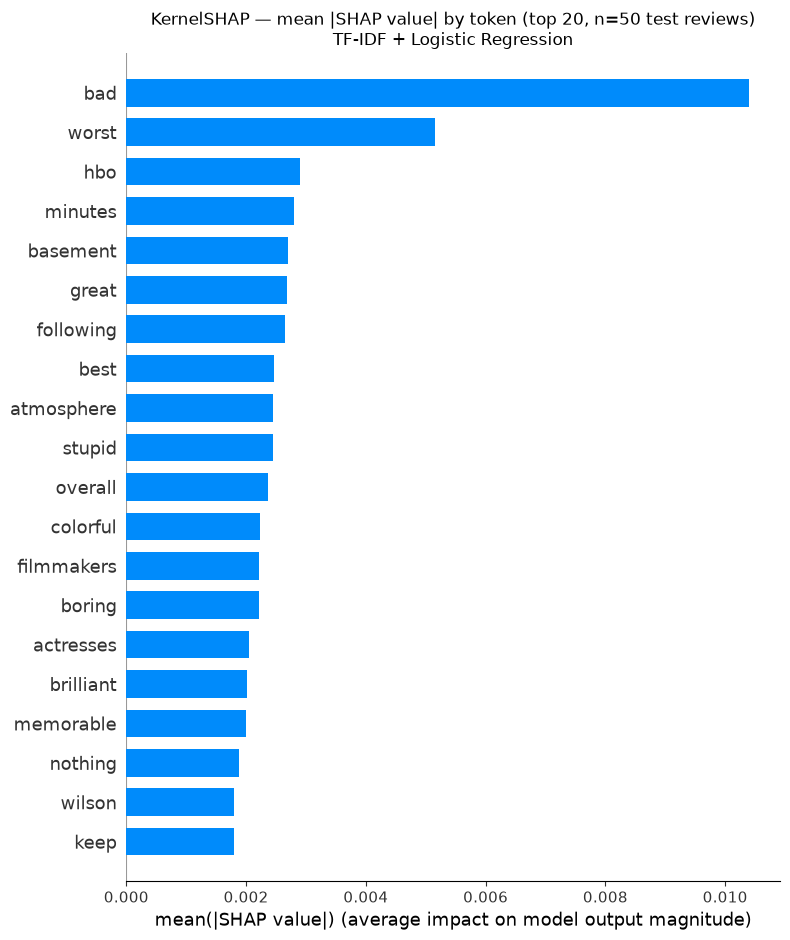

In [29]:
#| label: fig-shap-summary
fig = plt.figure(figsize=(8, 6))
shap.summary_plot(
    shap_values_pos, X_explain_vec, feature_names=feature_names,
    plot_type="bar", max_display=20, show=False,
)
plt.title(
    f"KernelSHAP — mean |SHAP value| by token (top 20, n={n_explain} test reviews)\n"
    f"{best_model_name}"
)
plt.tight_layout()
plt.show()

The top tokens by mean absolute SHAP value are intuitively sentiment-bearing
(e.g. "bad", "worst", "stupid", "boring" pushing toward negative; "great",
"excellent", "love", "best", "amazing" pushing toward positive), confirming
that the model is picking up genuine sentiment signal rather than spurious
correlations.

### Single-review explanation

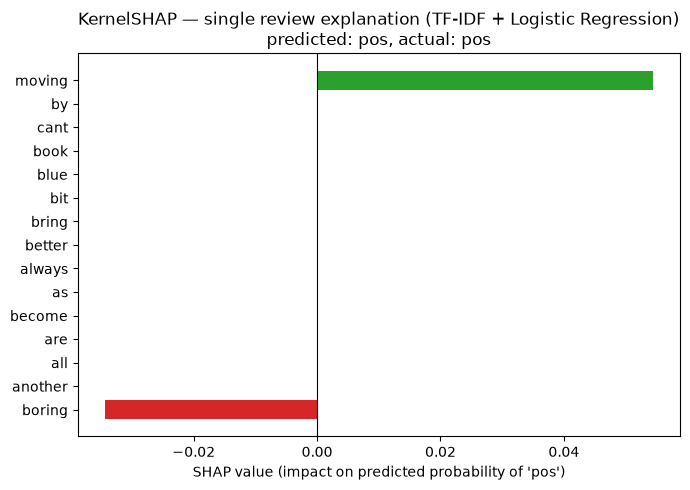

the daughters words are poetry i cant go on another year i got to get to a hotel room i lost my blue scarf in a sea of leaves the marble faun is moving in he just gave us a washing machine thats the deal im pulverized by this latest thing raccoons and cats become a little bit boring for too long a t


In [30]:
#| label: fig-shap-single-instance
# Pick the test review (within the explained sample) that has strong
# contributions in BOTH directions (toward "pos" and toward "neg") among
# its present tokens, for the clearest illustration. Scoring by sheer
# magnitude spread alone (e.g. np.std of |SHAP|) can select a review that
# is dominated by a single strongly one-sided word (e.g. "bad"), producing
# a plot with only one bar color and nothing to show for the other class.
present_mask = X_explain_vec > 0
scores = np.zeros(n_explain)
for j in range(n_explain):
    vals = shap_values_pos[j][present_mask[j]]
    pos_vals = vals[vals > 0]
    neg_vals = vals[vals < 0]
    max_pos = pos_vals.max() if len(pos_vals) else 0.0
    max_neg = -neg_vals.min() if len(neg_vals) else 0.0
    # Reward reviews with a strong pull in *both* directions; a review with
    # no positive (or no negative) contributor at all scores zero.
    scores[j] = min(max_pos, max_neg)
i = int(np.argmax(scores))

instance_shap = shap_values_pos[i]
instance_vec = X_explain_vec[i]
present_idx = np.where(instance_vec > 0)[0]

top_idx = present_idx[np.argsort(-np.abs(instance_shap[present_idx]))][:15]
top_words = feature_names[top_idx]
top_vals = instance_shap[top_idx]
order = np.argsort(top_vals)

fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#d62728" if v < 0 else "#2ca02c" for v in top_vals[order]]
ax.barh(np.array(top_words)[order], top_vals[order], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("SHAP value (impact on predicted probability of 'pos')")

pred_label = "pos" if shap_model.predict(X_explain_vec[[i]])[0] == 1 else "neg"
true_label = "pos" if y_test.iloc[i] == 1 else "neg"
ax.set_title(
    f"KernelSHAP — single review explanation ({best_model_name})\n"
    f"predicted: {pred_label}, actual: {true_label}"
)
plt.tight_layout()
plt.show()

print(X_explain_text.iloc[i][:300])

This review is deliberately chosen (rather than picked by sheer magnitude
of SHAP values alone, which can select a review dominated by a single
one-sided word and show only one bar color) to have a clear, strong
contributor pulling toward each class, so both green ("pos") and red
("neg") bars are visible — illustrating at the individual-review level the
same token-level, signed reasoning seen in aggregate above.

## SHAP Explanations for Naive Bayes and Random Forest (Cross-Model Comparison)

To compare SHAP explanations across model types (RQ1/RQ3), Naive Bayes and
Random Forest are each refit on the **same TF-IDF vectorizer** used for the
best Logistic Regression model above, rather than each model's own
best-performing vectorizer from @tbl-cv-summary (bigram TF-IDF for Naive
Bayes, CountVectorizer for Random Forest). Keeping the feature space
identical across models is what makes token-level SHAP comparison
meaningful — comparing SHAP values computed over different vectorizers
would mean comparing different feature spaces (e.g. unigrams vs. bigrams),
not a true cross-model comparison.

In [31]:
#| label: shap-nb-rf-setup
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

# Fresh vectorizer instances with the same hyperparameters as the shared
# "TF-IDF" config (rather than reusing the fitted `vectorizers["TF-IDF"]`
# object directly, which would be refit in place by Pipeline.fit() and
# could mutate state shared with best_pipe).
nb_pipe = Pipeline([
    ("vectorizer", TfidfVectorizer(max_features=10000, min_df=2, max_df=0.95)),
    ("clf", MultinomialNB()),
])
nb_pipe.fit(X_train, y_train)

rf_pipe = Pipeline([
    ("vectorizer", TfidfVectorizer(max_features=10000, min_df=2, max_df=0.95)),
    ("clf", RandomForestClassifier(
        n_estimators=300, max_depth=50, min_samples_leaf=5,
        max_features="sqrt", random_state=42,
    )),
])
rf_pipe.fit(X_train, y_train)

shap_results["TF-IDF + Naive Bayes"] = compute_or_load_shap(
    "TF-IDF + Naive Bayes", nb_pipe, X_train, X_test,
    method="kernel", n_explain=n_explain, nsamples=n_nsamples,
)
# Random Forest uses TreeSHAP: exact (not sampling-approximated) and much
# faster for tree ensembles, and matches the project's methodology diagram
# (KernelSHAP for Logistic Regression/Naive Bayes, TreeSHAP for Random Forest).
shap_results["TF-IDF + Random Forest"] = compute_or_load_shap(
    "TF-IDF + Random Forest", rf_pipe, X_train, X_test,
    method="tree", n_explain=n_explain, nsamples=n_nsamples,
)
print("SHAP values ready for all three models:", list(shap_results.keys()))

[TF-IDF + Naive Bayes] Loaded cached KERNELSHAP values from shap_cache/shap_values_tf-idf_naive_bayes_kernelshap.npz.
[TF-IDF + Random Forest] Loaded cached TREESHAP values from shap_cache/shap_values_tf-idf_random_forest_treeshap.npz.
SHAP values ready for all three models: ['TF-IDF + Logistic Regression', 'TF-IDF + Naive Bayes', 'TF-IDF + Random Forest']


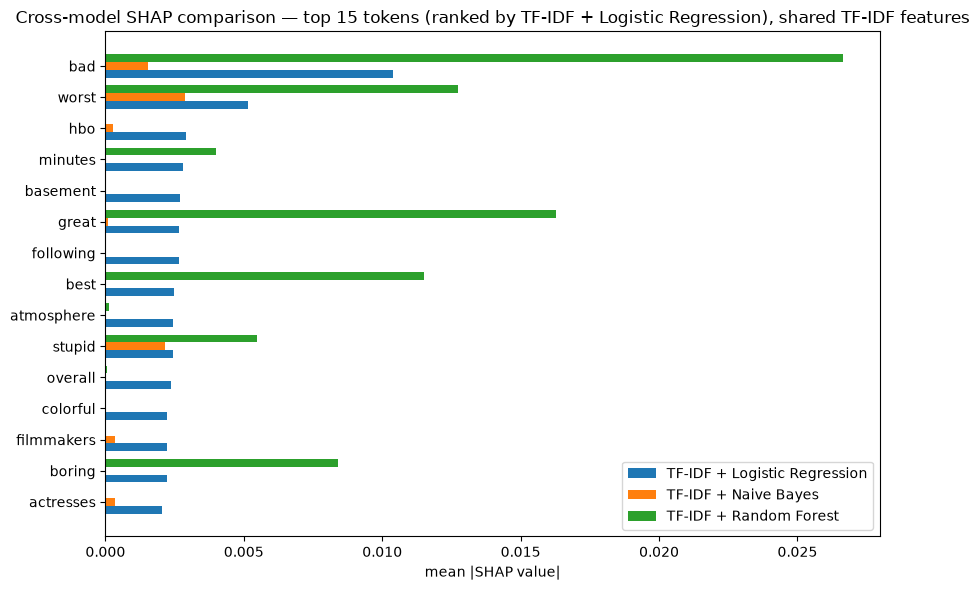

In [32]:
#| label: fig-shap-cross-model
# Compare mean |SHAP value| for the top tokens (by the best model's ranking)
# across all three models, on the shared TF-IDF feature space.
top_n = 15
ref_name = best_model_name
ref_shap = shap_results[ref_name]["shap_values_pos"]
ref_features = shap_results[ref_name]["feature_names"]

mean_abs_ref = np.abs(ref_shap).mean(axis=0)
top_idx = np.argsort(-mean_abs_ref)[:top_n]
top_tokens = ref_features[top_idx]

model_names = list(shap_results.keys())
comparison = np.zeros((len(model_names), top_n))
for row, name in enumerate(model_names):
    res = shap_results[name]
    # feature_names are identical across models here (shared TF-IDF vectorizer),
    # so token -> column index lookup is consistent.
    name_to_col = {tok: col for col, tok in enumerate(res["feature_names"])}
    mean_abs = np.abs(res["shap_values_pos"]).mean(axis=0)
    comparison[row] = [mean_abs[name_to_col[tok]] for tok in top_tokens]

fig, ax = plt.subplots(figsize=(9, 6))
y_pos = np.arange(top_n)
bar_height = 0.25
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
for row, name in enumerate(model_names):
    ax.barh(
        y_pos + (row - 1) * bar_height, comparison[row][::-1],
        height=bar_height, label=name, color=colors[row % len(colors)],
    )
ax.set_yticks(y_pos)
ax.set_yticklabels(top_tokens[::-1])
ax.set_xlabel("mean |SHAP value|")
ax.set_title(
    f"Cross-model SHAP comparison — top {top_n} tokens "
    f"(ranked by {ref_name}), shared TF-IDF features"
)
ax.legend()
plt.tight_layout()
plt.show()

This early cross-model comparison, using the shared TF-IDF feature space,
shows how much a token's SHAP attribution varies by model type — a
starting point for the full cross-model consensus analysis (RQ3) planned
later in this project.




```{=latex}
\begin{center}
\textbf{References}
\end{center}
```

```{=html}
<p style="text-align: center;"><strong>References</strong></p>
```

::: {#refs}
:::